<a href="https://colab.research.google.com/github/rons-12/fiap-tech-challenge-fase-2-wine-quality/blob/main/notebooks/01_wine_quality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tech Challenge - Fase 02
## Case Wine Quality

## Contexto

A indústria vitivinícola possui grande relevância econômica e cultural em
diversos países. Tradicionalmente, a avaliação da qualidade de um vinho é realizada
por especialistas, por meio de análises sensoriais, que consideram aspectos como
aroma, sabor, acidez e equilíbrio. No entanto, esse processo pode ser subjetivo e
demandar tempo, além de depender da experiência dos avaliadores.

Com o avanço das técnicas de ciência de dados e aprendizado de máquina,
tornou-se possível utilizar dados físico-químicos obtidos durante a produção do vinho
para auxiliar na previsão da qualidade final do produto. Dessa forma, modelos
preditivos podem apoiar enólogos e produtores na tomada de decisão, permitindo
ajustes no processo produtivo e contribuindo para a padronização da qualidade.

## Proposta

O objetivo será desenvolver e treinar um modelo de classificação que seja capaz de prever a qualidade do vinho com base nas características físico-quimicas. A variável que utilizaremos será a "quality" onde transformaremos em uma classificação binária, tendo como alvo, Vinho de Alta Qualidade em notas >=7 e Vinho de Qualidade comum em notas <7. Vale ressaltar que na base utilizada há somente vinhos tintos da variedade portuguesa Vinho Verde. Portanto as conclusões valem para este recorte.


### Fonte: https://www.kaggle.com/datasets/yasserh/wine-quality-dataset

# Setup

In [1]:
RANDOM_STATE = 42

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [3]:
URL = "https://raw.githubusercontent.com/rons-12/fiap-tech-challenge-fase-2-wine-quality/main/data/WineQT.csv"
df = pd.read_csv(URL)

# Etapa 1: Compreensão do Problema e preparação da base

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [5]:
df.shape

(1143, 13)

In [6]:
# Remoção da coluna "Id" (é apenas um índice, sem caracteristicas do vinho),
# e remoção das linhas duplicadas.

df = df.drop(columns="Id")
n_antes = len(df)
df = df.drop_duplicates()
df = df.reset_index(drop=True)

In [7]:
print(f"Duplicatas removidas:{n_antes - len(df)} | Linhas finais: {len(df)}")

Duplicatas removidas:125 | Linhas finais: 1018


In [8]:
# Criação de classificação binária.
# 1 = Alta Qualidade (nota >=7),
# 0 = Qualidade Comum (nota <7)
df["alta_qualidade"] = (df["quality"] >= 7).astype(int)

# Remoção das colunas "quality" e "alta_qualidade", pois elas são o resultado.
# Mante-las na variável X faria termos vazamento de dados.
x = df.drop(columns=["quality", "alta_qualidade"])
y = df["alta_qualidade"]
y.value_counts(normalize=True)

,proportion
alta_qualidade,
0,0.865422
1,0.134578


In [9]:
# Divisão treino/teste: 70/30. Mantemos assim aproximadametne
# 13,5% de vinhos bons em ambos os conjutos.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)

print(f"Treino: {x_train.shape[0]} vinhos ({y_train.mean():.1%} alta qualidade)")
print(f"Teste:  {x_test.shape[0]} vinhos ({y_test.mean():.1%} alta qualidade)")

Treino: 712 vinhos (13.5% alta qualidade)
Teste:  306 vinhos (13.4% alta qualidade)


In [10]:
x

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8
4,7.4,0.660,0.00,1.8,0.075,13.0,40.0,0.99780,3.51,0.56,9.4
...,...,...,...,...,...,...,...,...,...,...,...
1013,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0
1014,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5
1015,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5
1016,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2


# Etapa 2: Análise Exploratória - EDA
Como primeiro passo, vamos entender o comportamento estatístico dos dados físico-químicos (como acidez, pH, teor alcoólico).

## 2.1 - Investigando a distribuição das variáveis e detectando outliers

In [11]:
## Visão geral do Dataframe após as transformações anteriores.
## A fim de validar se não ficou nada fora do lugar

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1018 entries, 0 to 1017
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1018 non-null   float64
 1   volatile acidity      1018 non-null   float64
 2   citric acid           1018 non-null   float64
 3   residual sugar        1018 non-null   float64
 4   chlorides             1018 non-null   float64
 5   free sulfur dioxide   1018 non-null   float64
 6   total sulfur dioxide  1018 non-null   float64
 7   density               1018 non-null   float64
 8   pH                    1018 non-null   float64
 9   sulphates             1018 non-null   float64
 10  alcohol               1018 non-null   float64
 11  quality               1018 non-null   int64  
 12  alta_qualidade        1018 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 103.5 KB


In [12]:
## Detectando a presença de valores nulos ou negativos/impossíveis

print("Valores nulos por colunas:", int(df.isnull().sum().sum()))
df.describe().T.round(3)

Valores nulos por colunas: 0


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1018.0,8.289,1.741,4.600,7.100,7.900,9.100,15.900
volatile acidity,1018.0,0.534,0.183,0.120,0.390,0.520,0.645,1.580
citric acid,1018.0,0.269,0.196,0.000,0.090,0.250,0.420,1.000
residual sugar,1018.0,2.524,1.315,0.900,1.900,2.200,2.600,15.500
chlorides,1018.0,0.087,0.049,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1018.0,15.649,10.177,1.000,7.000,13.000,21.000,68.000
total sulfur dioxide,1018.0,46.326,33.124,6.000,21.000,38.000,62.000,289.000
density,1018.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1018.0,3.312,0.158,2.740,3.210,3.310,3.400,4.010
sulphates,1018.0,0.657,0.168,0.330,0.550,0.620,0.720,2.000


Não há valores nulos nem valores impossíveis.

## 2.2 - Distribuição das variáveis

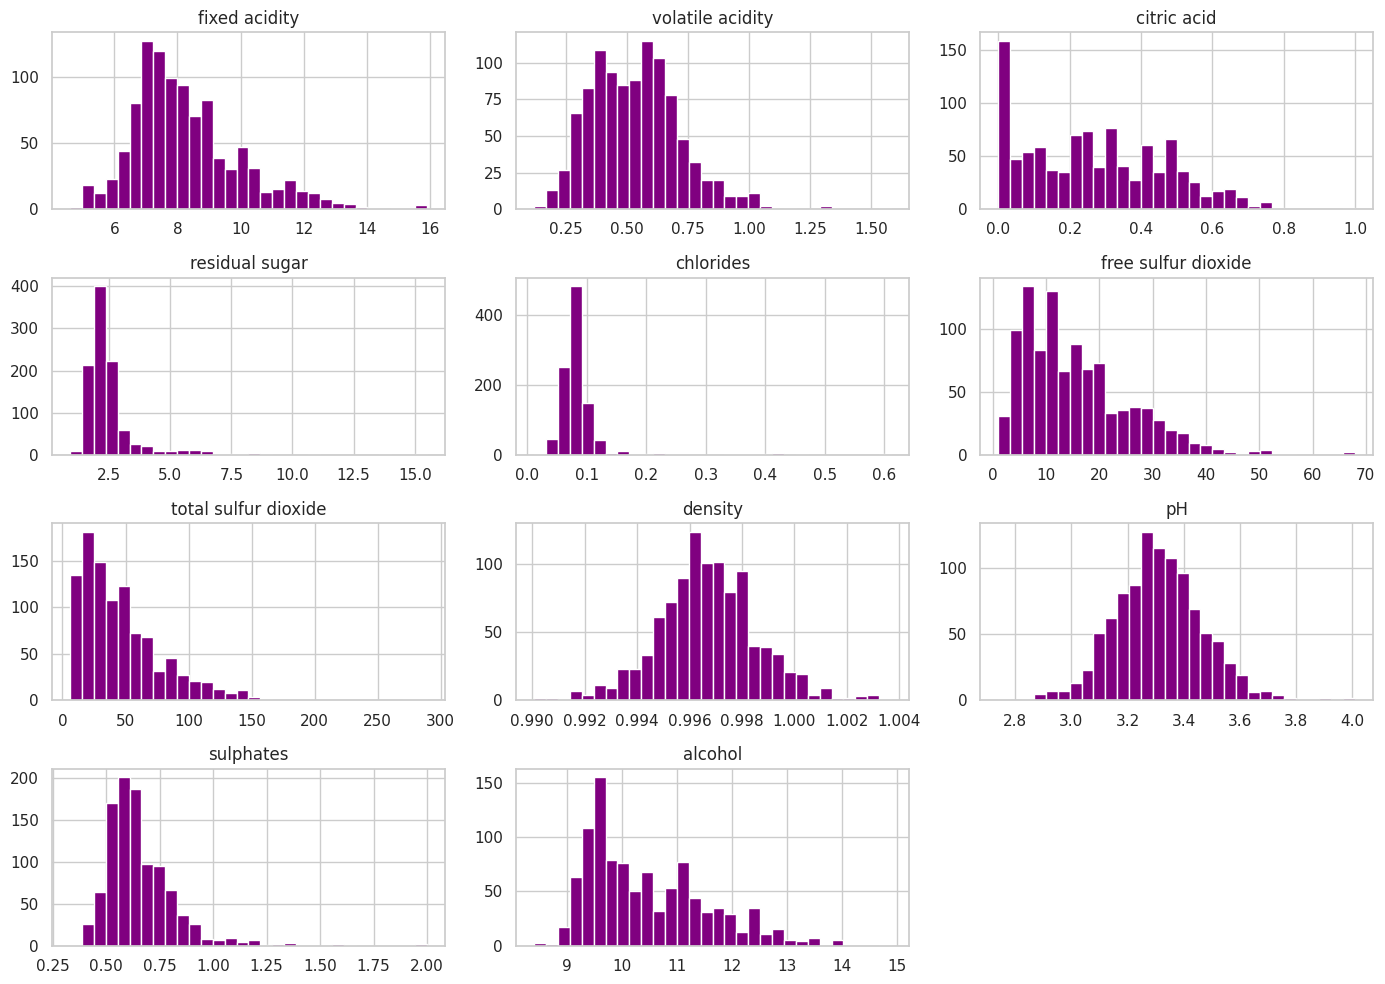

In [13]:
# (Utilizei a distribuição que a Fernanda fez mesclado ao que o Rafael realizou)

sns.set_theme(style="whitegrid")

x.hist(bins=30, figsize=(14, 10), color="purple")
plt.tight_layout()
plt.savefig("hist_variaveis.png", dpi=150)
plt.show()

In [14]:
# Quanto maior a assimetria, mais longa a cauda à direita
x.skew().sort_values(ascending=False).round(2).to_frame("assimetria")

,assimetria
chlorides,5.93
residual sugar,4.35
sulphates,2.42
total sulfur dioxide,1.68
free sulfur dioxide,1.17
fixed acidity,1.04
alcohol,0.85
volatile acidity,0.72
citric acid,0.37
pH,0.26


Podemos notar que as variáveis cloretos *(chlorides)*, açucar residual *(residual sugar)*, sulfatos *(sulphates)* e dióxido de enxofre total *(total sulfur dioxide)* apresentam uma forte assimetria à direita, sendo que a maioria dos vinhos concentram valores baixos, com poucos casos extremos, isso pode indicar possíveis outiliers. Para essas variáveis a mediana é mais indicada por descrever melhor o vinho, do que a média.

Outro ponto, é outras variáveis como densidade *(density)*, pH e ácido cítrico *(citric acid)* tem uma distribuição mais próxima da simétrica.

## 2.3 - Balanceamento das Classes

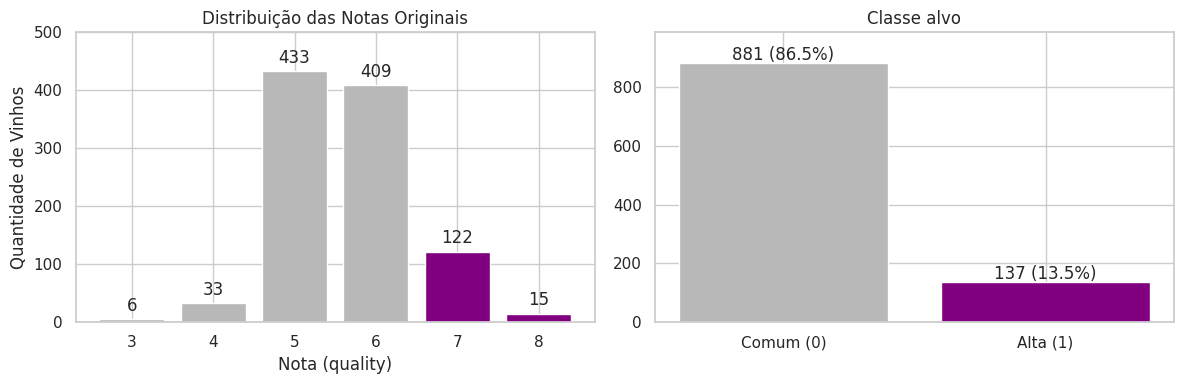

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

notas = df["quality"].value_counts().sort_index()
ax[0].bar(notas.index.astype(str), notas.values,
          color=["purple" if n >= 7 else "#b8b8b8" for n in notas.index])
ax[0].set_title("Distribuição das Notas Originais")
ax[0].set_xlabel("Nota (quality)")
ax[0].set_ylabel("Quantidade de Vinhos")

classes = y.value_counts().sort_index()
ax[1].bar(["Comum (0)", "Alta (1)"], classes.values, color=["#b8b8b8", "purple"])
ax[1].set_title("Classe alvo")
ax[1].set_ylim(0, classes.max() * 1.12)
for i, v in enumerate(classes.values):
  ax[1].text(i, v + 10, f"{v} ({v/len(y):.1%})", ha="center")

ax[0].bar_label(ax[0].containers[0], padding=3)

ax[0].set_ylim(0, ax[0].get_ylim()[1] * 1.1)

plt.tight_layout()
plt.savefig("balanceamento_classes.png", dpi=150)
plt.show()

**O que observamos aqui:** 881 vinhos receberam notas de 3 a 6 e são classificados como vinhos comuns (86,5%). A maior parte parte deles recebeu nota 5 ou 6 (842). Como sabemos, os especialistas dificilmente dão notas extremas, com isso temos 137 vinhos que receberam notas maiores que 7, representando 13,5% de vinhos de Alta classe.

## 2.4 - Correlações
A matriz de correlação ajuda a entender quais características físico-químicas mais influenciam a nota do vinho (e a nossa variável target).

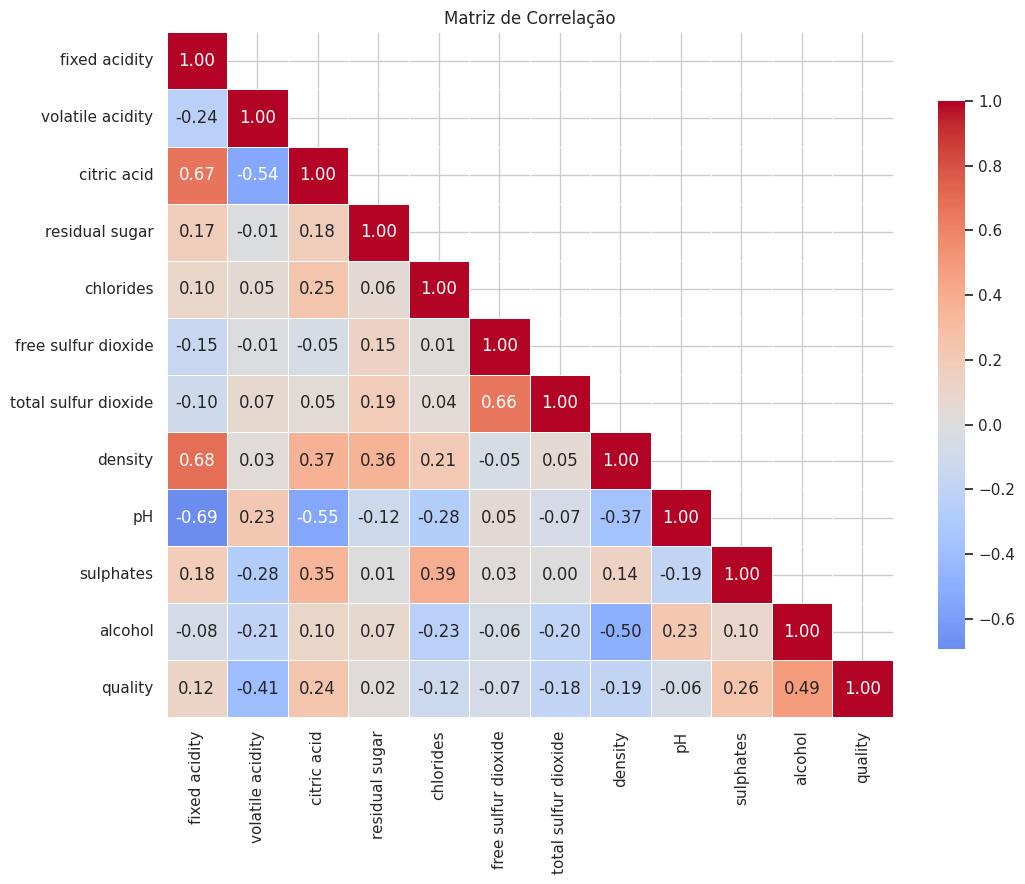

,correlação com quality
volatile acidity,-0.41
density,-0.19
total sulfur dioxide,-0.18
chlorides,-0.12
free sulfur dioxide,-0.07
pH,-0.06
residual sugar,0.02
fixed acidity,0.12
citric acid,0.24
sulphates,0.26


In [16]:
# Calculando a matriz de correlação
corr = df.drop(columns="alta_qualidade").corr()

plt.figure(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', center=0,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Matriz de Correlação')
plt.tight_layout()
plt.savefig("matriz_correlacao.png", dpi=150)

plt.show()


corr["quality"].drop("quality").sort_values().round(2).to_frame("correlação com quality")

`(Texto base da Fernanda, com valores recalculados)`

**Correlações com a qualidade:**


1.   **Teor Alcoólico (alcohol, +0,48):** Vinhos de maior qualidade tendem a apresentar uma correlação positiva moderada/forte com o teor alcoólico;
2.   **Acidez Volátil (volatile acidity, -0,41):** Apresentou uma correlação negativa com a qualidade, pois níveis muito altos de acidez volátil dão um sabor desagradável (vinagre) ao vinho;
3.   **Sulfatos (sulphates, +0,26):** Níveis adequados de sulfatos funcionam como um indicador de estabilidade e bom armazenamento, protegendo o vinho contra oxidações que degradariam a nota;
4.   **Ácido cítrico (citric acid, +0,24):** contribui com frescor.

**Correlações entre as variáveis:** fixed acidity se relaciona com citric acid (+0,67), density (+0,68) e pH (−0,69), o que é esperado quimicamente (mais ácido → pH menor). free e total sulfur dioxide também andam juntos (+0,66). Nenhum par passa de 0,7, então não há redundância grave a ponto de exigir remover variáveis.

## 2.5 - A diferença entre um vinho bom de um comum

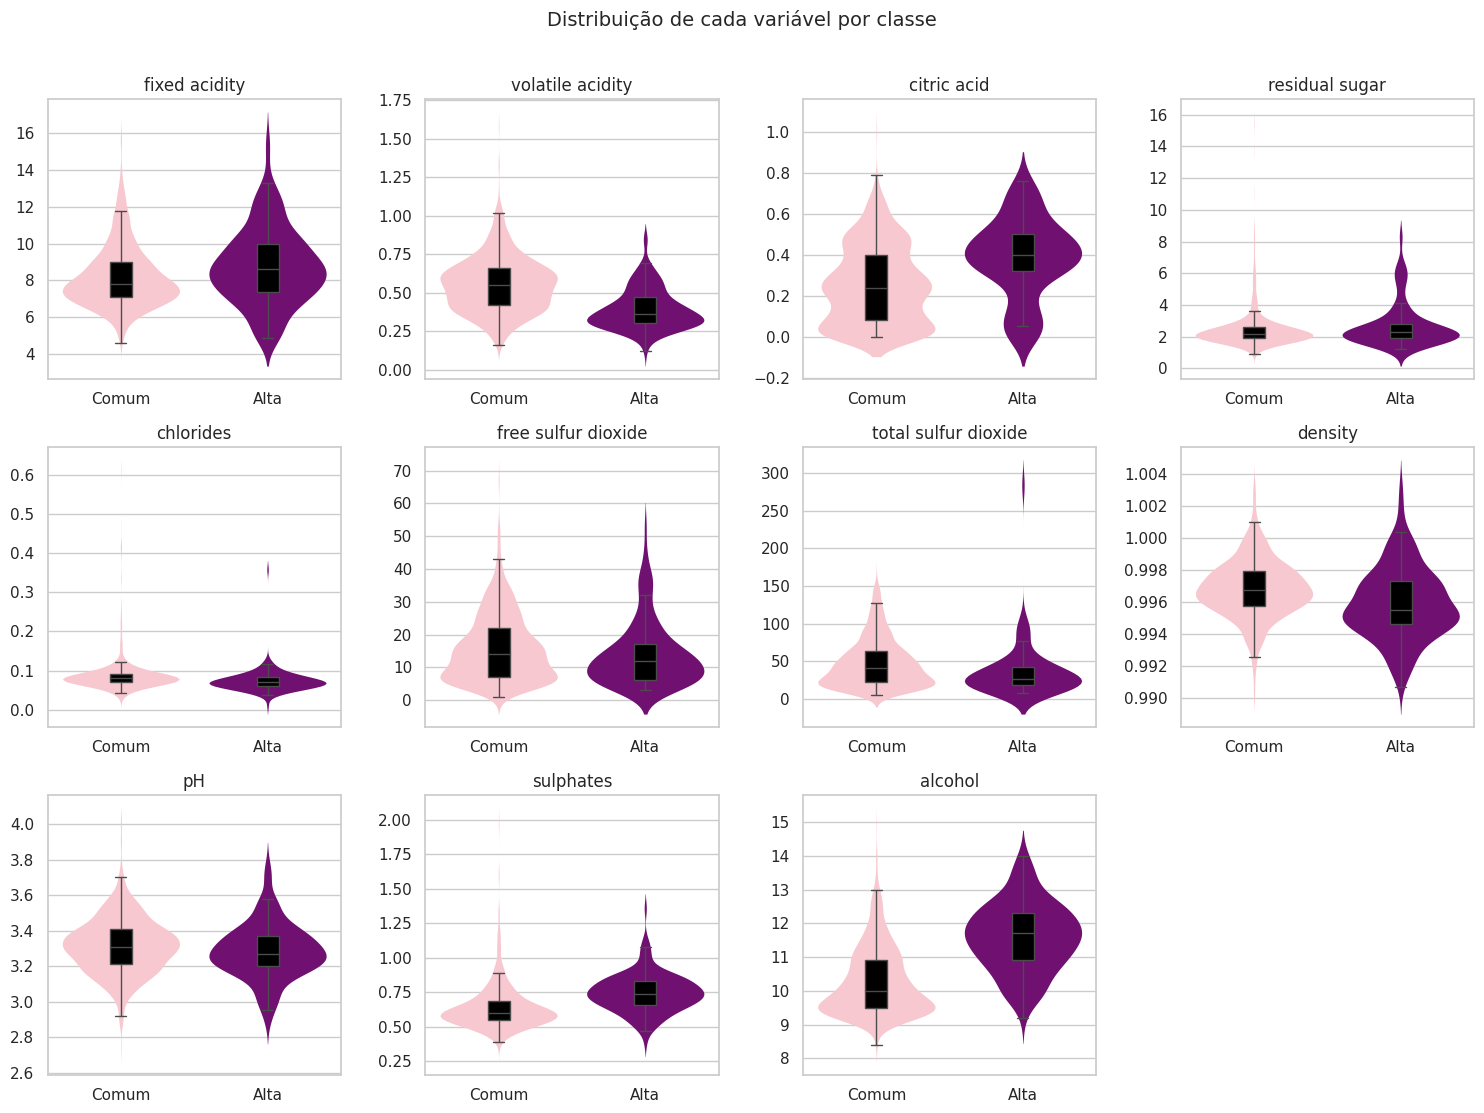

alta_qualidade,mediana comum,mediana alta
fixed acidity,7.800,8.600
volatile acidity,0.550,0.360
citric acid,0.240,0.400
residual sugar,2.200,2.300
chlorides,0.080,0.071
free sulfur dioxide,14.000,12.000
total sulfur dioxide,41.000,27.000
density,0.997,0.995
pH,3.310,3.270
sulphates,0.600,0.740


In [17]:
## grafico do violino + boxplot por classe - base do Rafael com ajuste na figura e paleta para seguirmos um padrão

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(15, 11))
axes = axes.flatten()
paleta = {0: "pink", 1: "purple"}

for i, col in enumerate(x.columns):
    sns.violinplot(data=df, x='alta_qualidade', y=col, hue="alta_qualidade", palette=paleta,
                   ax=axes[i], inner=None, legend=False, linewidth=0, density_norm="width")
    sns.boxplot(data=df, x="alta_qualidade", y=col, ax=axes[i], width=0.15,
                showfliers=False, boxprops={"facecolor": "black"})
    axes[i].set_title(col); axes[i].set_xlabel(""); axes[i].set_ylabel("")
    axes[i].set_xticks([0, 1], ["Comum", "Alta"])

fig.delaxes(axes[-1])
plt.suptitle("Distribuição de cada variável por classe", y=1.01, fontsize=14)
plt.tight_layout()
plt.savefig("variaveis_por_classes.png", dpi=150, bbox_inches="tight")
plt.show()

df.groupby("alta_qualidade")[list(x.columns)].median().T.rename(
    columns={0: "mediana comum", 1: "mediana alta"}).round(3)

Comparando as medianas das duas classes, os vinhos de alta qualidade têm:

- **Mais álcool** (11,7% contra 10,0%), a diferença mais visível no gráfico;
- **Menos acidez volátil** (0,36 contra 0,55);
- **Mais sulfatos** (0,74 contra 0,60) e mais ácido cítrico (0,40 contra 0,24);
- **Menos dióxido de enxofre total** (27 contra 41).

Já residual sugar, pH e free sulfur dioxide praticamente não mudam entre as classes, o que sugere baixo poder de separação para essas variáveis